# 🏥 LiverGuardian — MRI Inference
### Upload a ZIP file containing 8 MRI phases (+ optional label) to get a diagnosis

In [1]:
# ── Cell 1: Imports ──
import torch
import torch.nn as nn
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import zipfile, tempfile, os, sys
from pathlib import Path
from skimage.transform import resize as sk_resize

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [2]:
# ── Cell 2: Config ──
TARGET_SHAPE = (32, 96, 96)

SCAN_TYPES = ['C-pre', 'C+A', 'C+V', 'C+Delay', 'T2WI', 'DWI', 'In Phase', 'Out Phase']

MALIGNANT_NAME = {0: 'Intrahepatic Cholangiocarcinoma', 1: 'Hepatic Metastasis', 2: 'Hepatocellular Carcinoma'}
BENIGN_NAME    = {0: 'Hepatic Hemangioma', 1: 'Hepatic Abscess', 2: 'Hepatic Cyst', 3: 'Focal Nodular Hyperplasia'}

# غير الـ path لمكان الـ models عندك
BASE_PATH       = r'E:\TAAA7\Graduation project\MRI\New_MRI (3D)\connection_MRI'
SEG_MODEL1_PATH = BASE_PATH + r'\best_seg_model1_DWI.pth'
SEG_MODEL2_PATH = BASE_PATH + r'\best_seg_model2_T2WI.pth'
SEG_MODEL3_PATH = BASE_PATH + r'\best_seg_model3_cascade.pth'
CLS_MODEL1_PATH = BASE_PATH + r'\best_cls_model1_malignant.pth'
CLS_MODEL2_PATH = BASE_PATH + r'\best_cls_model2_malignant_type.pth'
CLS_MODEL3_PATH = BASE_PATH + r'\best_cls_model3_benign_type.pth'

print('Config done!')

Config done!


In [48]:
# ── Cell 3: Helper Functions ──
import torch.nn.functional as F

def load_nifti(path):
    return nib.load(str(path)).get_fdata().astype(np.float32)

def normalize(vol):
    mean = vol.mean()
    std  = vol.std()
    if std > 0:
        return (vol - mean) / std
    return vol - mean

def resize_volume(vol, target_shape):
    t = torch.tensor(vol).unsqueeze(0).unsqueeze(0)
    r = F.interpolate(t, size=target_shape, mode='trilinear', align_corners=False)
    return r.squeeze().numpy()

def resize_mask(mask, target_shape):
    t = torch.tensor(mask).unsqueeze(0).unsqueeze(0)
    r = F.interpolate(t, size=target_shape, mode='nearest')
    return r.squeeze().numpy()

print('Helper functions ready!')

Helper functions ready!


In [4]:
# ── Cell 4: Model Architectures ──
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.GELU(),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch)
        )
        self.skip = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm3d(out_ch)
        ) if in_ch != out_ch else nn.Identity()
        self.act = nn.GELU()

    def forward(self, x):
        return self.act(self.block(x) + self.skip(x))

class ResUNet3D(nn.Module):
    def __init__(self, in_ch=1):
        super().__init__()
        self.enc1 = ResBlock(in_ch, 32)
        self.enc2 = ResBlock(32,    64)
        self.enc3 = ResBlock(64,   128)
        self.enc4 = ResBlock(128,  256)
        self.pool = nn.MaxPool3d(2)
        self.bottleneck = ResBlock(256, 512)
        self.up4  = nn.ConvTranspose3d(512, 256, 2, stride=2)
        self.dec4 = ResBlock(512, 256)
        self.up3  = nn.ConvTranspose3d(256, 128, 2, stride=2)
        self.dec3 = ResBlock(256, 128)
        self.up2  = nn.ConvTranspose3d(128, 64,  2, stride=2)
        self.dec2 = ResBlock(128, 64)
        self.up1  = nn.ConvTranspose3d(64,  32,  2, stride=2)
        self.dec1 = ResBlock(64,  32)
        self.seg_out = nn.Conv3d(32, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b),  e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return torch.sigmoid(self.seg_out(d1))

class ResBlock3D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.GELU(),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch))
        self.skip = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, stride=stride, bias=False),
            nn.BatchNorm3d(out_ch)
        ) if in_ch != out_ch or stride != 1 else nn.Identity()
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(self.block(x) + self.skip(x))

class ResNet3D(nn.Module):
    def __init__(self, in_ch=9, num_classes=2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv3d(in_ch, 32, 3, padding=1, bias=False),
            nn.BatchNorm3d(32), nn.GELU())
        self.layer1 = ResBlock3D(32,  64,  stride=2)
        self.layer2 = ResBlock3D(64,  128, stride=2)
        self.layer3 = ResBlock3D(128, 256, stride=2)
        self.layer4 = ResBlock3D(256, 512, stride=2)
        self.cls_head = nn.Sequential(
            nn.AdaptiveAvgPool3d(1), nn.Flatten(),
            nn.Linear(512, 256), nn.GELU(), nn.Dropout(0.5),
            nn.Linear(256, 128), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes))
    def forward(self, x, mask):
        inp = torch.cat([x, mask], dim=1)
        x   = self.stem(inp)
        x   = self.layer1(x)
        x   = self.layer2(x)
        x   = self.layer3(x)
        x   = self.layer4(x)
        return self.cls_head(x)

print('Architectures defined!')

Architectures defined!


In [49]:
# ── Cell 5: Load Models ──
seg_model1 = ResUNet3D(in_ch=1).to(device)
seg_model2 = ResUNet3D(in_ch=2).to(device)
seg_model3 = ResUNet3D(in_ch=2).to(device)
cls_model1 = ResNet3D(in_ch=9, num_classes=2).to(device)
cls_model2 = ResNet3D(in_ch=9, num_classes=3).to(device)
cls_model3 = ResNet3D(in_ch=9, num_classes=4).to(device)

dummy_img  = torch.randn(1, 8, *TARGET_SHAPE).to(device)
dummy_mask = torch.randn(1, 1, *TARGET_SHAPE).to(device)
with torch.no_grad():
    cls_model1(dummy_img, dummy_mask)
    cls_model2(dummy_img, dummy_mask)
    cls_model3(dummy_img, dummy_mask)

seg_model1.load_state_dict(torch.load(SEG_MODEL1_PATH, map_location=device, weights_only=False)['model_state'])
seg_model2.load_state_dict(torch.load(SEG_MODEL2_PATH, map_location=device, weights_only=False)['model_state'])
seg_model3.load_state_dict(torch.load(SEG_MODEL3_PATH, map_location=device, weights_only=False)['model_state'])
cls_model1.load_state_dict(torch.load(CLS_MODEL1_PATH, map_location=device, weights_only=False)['model_state'])
cls_model2.load_state_dict(torch.load(CLS_MODEL2_PATH, map_location=device, weights_only=False)['model_state'])
cls_model3.load_state_dict(torch.load(CLS_MODEL3_PATH, map_location=device, weights_only=False)['model_state'])

for m in [seg_model1, seg_model2, seg_model3, cls_model1, cls_model2, cls_model3]:
    m.eval()

print('All 6 models loaded!')

All 6 models loaded!


In [94]:
# ── Cell 6: Upload ZIP ──
import tkinter as tk
from tkinter import filedialog

def upload_zip():
    root = tk.Tk()
    root.withdraw()
    root.attributes('-topmost', True)
    path = filedialog.askopenfilename(
        title='اختار الـ ZIP file بتاع المريض',
        filetypes=[('ZIP files', '*.zip')]
    )
    root.destroy()
    return path

zip_path = upload_zip()

if zip_path:
    tmp_dir = tempfile.mkdtemp()
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(tmp_dir)

    phase_files = {}
    label_path  = None

    for root_dir, dirs, files in os.walk(tmp_dir):
        for f in files:
            if not (f.endswith('.nii') or f.endswith('.nii.gz')):
                continue
            full_path = os.path.join(root_dir, f)
            # شيك لو label
            if 'label' in f.lower():
                label_path = full_path
                print(f'✅ Label: {f}')
                continue
            for phase in SCAN_TYPES:
                if phase.replace(' ', '') in f.replace(' ', ''):
                    phase_files[phase] = full_path
                    print(f'✅ {phase}: {f}')
                    break

    print(f'\nاتلقت {len(phase_files)} phases من {len(SCAN_TYPES)} المطلوبين')
    print(f'Label: {"exit" if label_path else "not exit use predict"}')
else:
    print('Not exit file')

✅ C+A: MR-467988_5_C+A_0000.nii.gz
✅ C+Delay: MR-467988_5_C+Delay_0000.nii.gz
✅ C+V: MR-467988_5_C+V_0000.nii.gz
✅ C-pre: MR-467988_5_C-pre_0000.nii.gz
✅ DWI: MR-467988_5_DWI_0000.nii.gz
✅ In Phase: MR-467988_5_InPhase_0000.nii.gz
✅ Out Phase: MR-467988_5_OutPhase_0000.nii.gz
✅ T2WI: MR-467988_5_T2WI_0000.nii.gz

اتلقت 8 phases من 8 المطلوبين
Label: not exit use predict


In [95]:
# ── Cell 7: Predict ──
def predict_from_files(phase_files):
    volumes = []
    for phase in SCAN_TYPES:
        path = phase_files.get(phase, None)
        vol  = normalize(load_nifti(path)) if path else np.zeros(TARGET_SHAPE, dtype=np.float32)
        volumes.append(resize_volume(vol, TARGET_SHAPE))
    image = torch.tensor(np.stack(volumes), dtype=torch.float32).unsqueeze(0).to(device)

    dwi_path = phase_files.get('DWI', None)
    t2_path  = phase_files.get('T2WI', None)
    dwi = resize_volume(normalize(load_nifti(dwi_path)), TARGET_SHAPE) if dwi_path else np.zeros(TARGET_SHAPE, dtype=np.float32)
    t2  = resize_volume(normalize(load_nifti(t2_path)),  TARGET_SHAPE) if t2_path  else np.zeros(TARGET_SHAPE, dtype=np.float32)

    with torch.no_grad():
        dwi_t      = torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        mask1      = seg_model1(dwi_t).squeeze(0)

        t2_inp     = torch.cat([torch.tensor(t2, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                                mask1.unsqueeze(0)], dim=1)
        mask2      = seg_model2(t2_inp).squeeze(0)

        d_inp      = torch.cat([torch.tensor(dwi, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device),
                                mask2.unsqueeze(0)], dim=1)
        final_mask = seg_model3(d_inp).squeeze(0).unsqueeze(0)
        
        bin_logits   = cls_model1(image, final_mask)
        bin_probs    = torch.softmax(bin_logits, dim=1)[0]
        is_malignant = bin_logits.argmax(1).item()
        bin_conf     = bin_probs[is_malignant].item()

        if is_malignant:
            type_logits = cls_model2(image, final_mask)
            type_probs  = torch.softmax(type_logits, dim=1)[0].cpu().numpy()
            type_idx    = type_logits.argmax(1).item()
            disease     = MALIGNANT_NAME[type_idx]
            type_conf   = type_probs[type_idx]
            type_map    = MALIGNANT_NAME
        else:
            type_logits = cls_model3(image, final_mask)
            type_probs  = torch.softmax(type_logits, dim=1)[0].cpu().numpy()
            type_idx    = type_logits.argmax(1).item()
            disease     = BENIGN_NAME[type_idx]
            type_conf   = type_probs[type_idx]
            type_map    = BENIGN_NAME

    # visualization على T2WI
    t2_vol   = load_nifti(t2_path) if t2_path else load_nifti(dwi_path)
    vis_mask = mask2[0].cpu().numpy()
    vis_mask = np.transpose(vis_mask, (1, 2, 0))  # (96, 96, 32)

    orig_mask = np.zeros(t2_vol.shape, dtype=np.float32)
    for i in range(vis_mask.shape[2]):
        sl_binary = (vis_mask[:,:,i] > 0.5).astype(np.float32)
        sl_idx    = min(i, t2_vol.shape[2]-1)
        orig_mask[:,:,sl_idx] = sk_resize(sl_binary, t2_vol.shape[:2],
                                           order=0, preserve_range=True)

    pred_best_sl = int(np.argmax([orig_mask[:,:,i].max() for i in range(orig_mask.shape[2])]))

    return {
        'disease':      disease,
        'is_malignant': is_malignant,
        'bin_conf':     bin_conf,
        'type_conf':    type_conf,
        'type_probs':   type_probs,
        'type_map':     type_map,
        'seg_mask':     orig_mask,
        'orig_vol':     normalize(t2_vol),
        'pred_best_sl': pred_best_sl,
    }

result = predict_from_files(phase_files)
print(f"Predicted: {'MALIGNANT' if result['is_malignant'] else 'BENIGN'} — {result['disease']}")

Predicted: BENIGN — Focal Nodular Hyperplasia


C:\Users\Omar\AppData\Local\Temp\ipykernel_23448\758878267.py:53: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


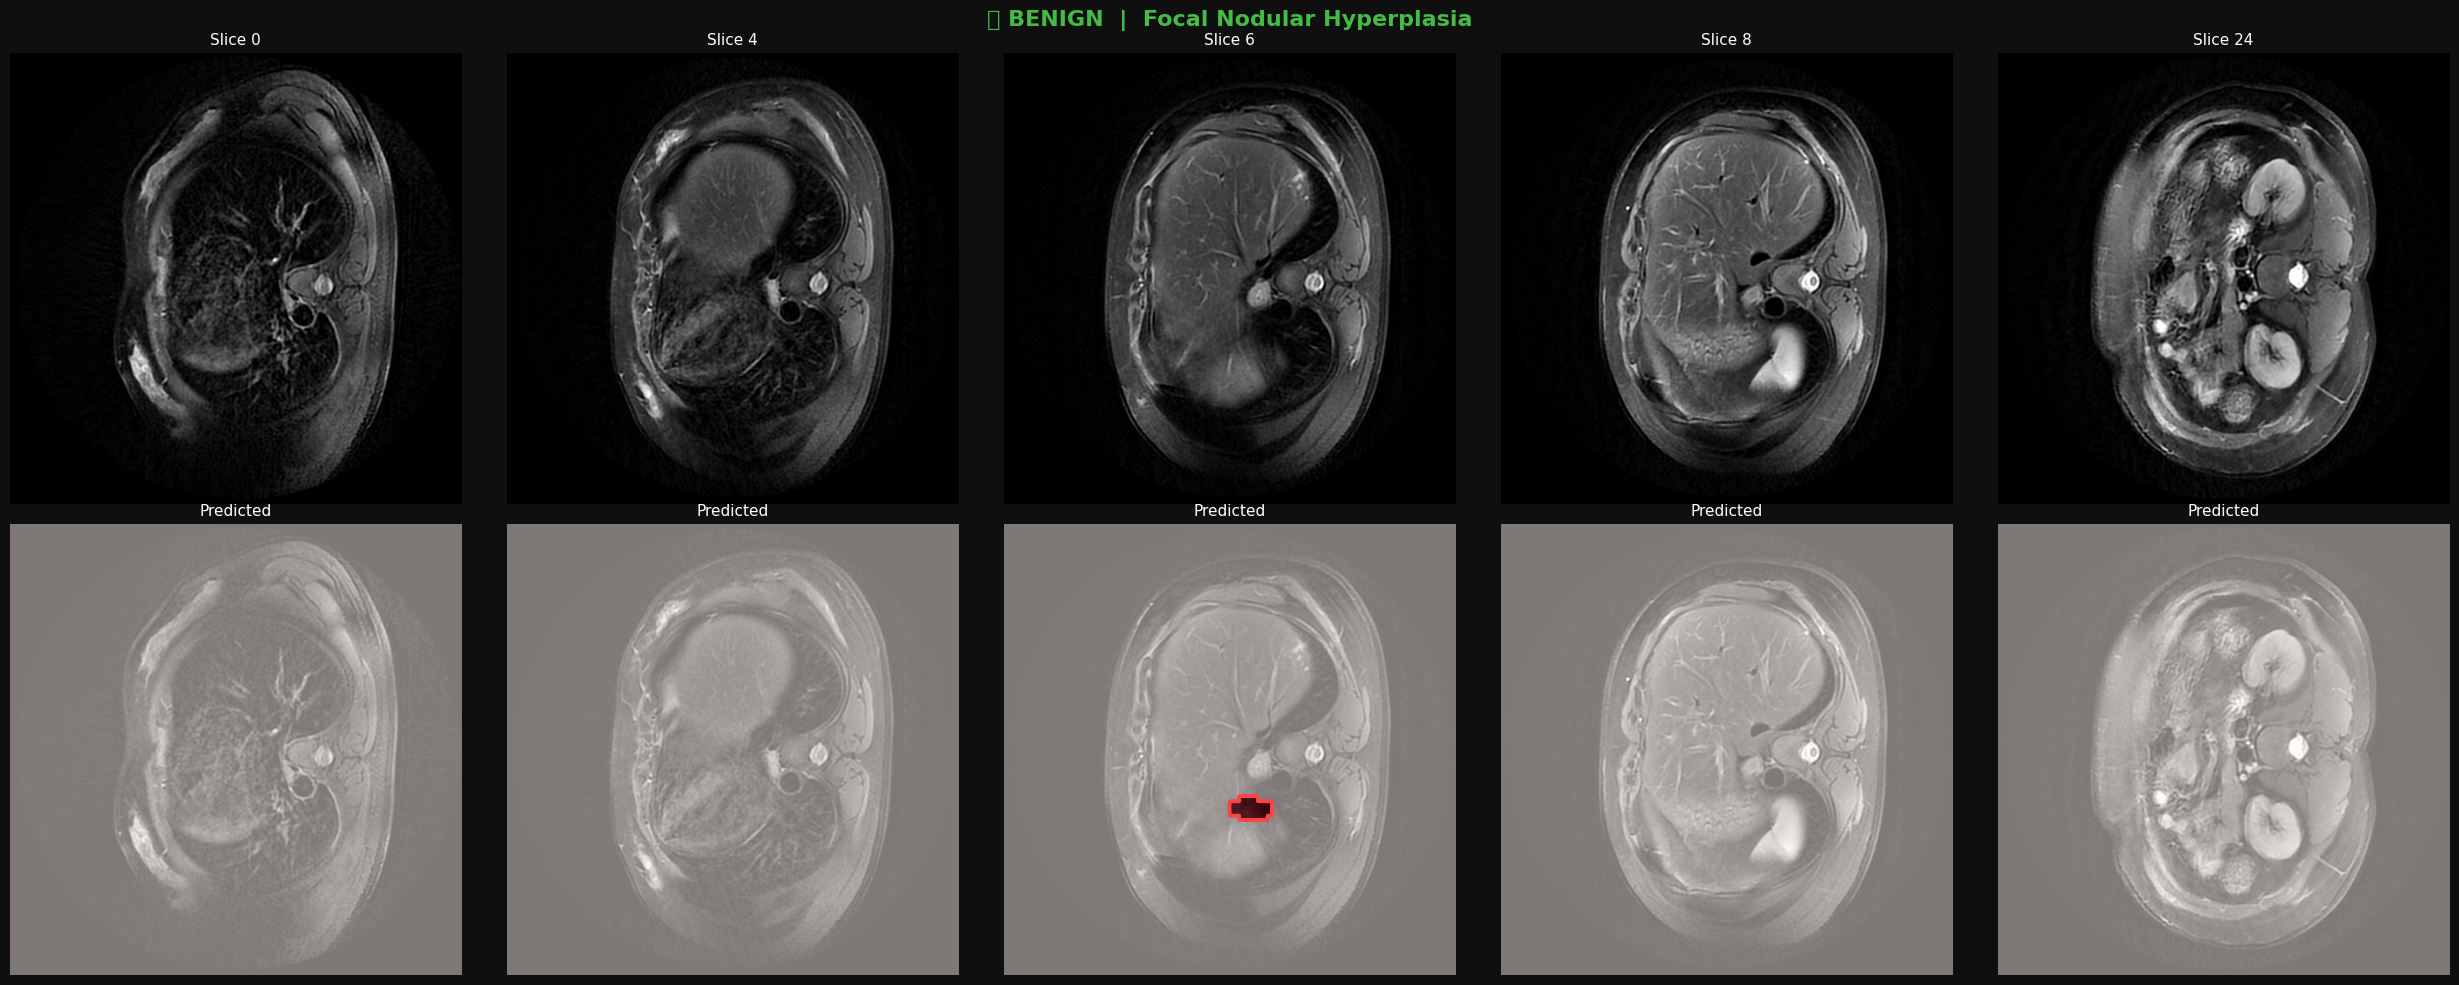

Type    : ✅ BENIGN
Disease : Focal Nodular Hyperplasia


In [98]:
# ── Cell 8: Visualize ──
def visualize_prediction(result, label_path=None):
    pred_mask    = result['seg_mask']
    orig_vol     = result['orig_vol']
    pred_best_sl = result['pred_best_sl']
    color        = '#ff4444' if result['is_malignant'] else '#44bb44'
    status       = '⚠️ MALIGNANT' if result['is_malignant'] else '✅ BENIGN'

    # شيك لو في label
    if label_path:
        gt_mask    = load_nifti(label_path)
        gt_best_sl = int(np.argmax([gt_mask[:,:,i].sum() for i in range(gt_mask.shape[2])]))
        best_sl    = gt_best_sl
        use_gt     = True
    else:
        best_sl = pred_best_sl
        use_gt  = False

    total_sl = orig_vol.shape[2]
    candidates = sorted(set([0, best_sl-2, best_sl, pred_best_sl, pred_best_sl+2, total_sl-1]))
    candidates = [max(0, min(s, total_sl-1)) for s in candidates]
# خد 5 بس
    step   = max(1, len(candidates) // 5)
    slices = candidates[::step][:5]
    if len(slices) < 5:
        slices = candidates[:5]

    fig, axes = plt.subplots(2, len(slices), figsize=(5*len(slices), 10))
    fig.patch.set_facecolor('#0f0f0f')
    fig.suptitle(f'{status}  |  {result["disease"]}',
                 fontsize=16, color=color, fontweight='bold')

    for i, sl in enumerate(slices):
        axes[0, i].imshow(orig_vol[:,:,sl], cmap='gray')
        axes[0, i].set_title(f'Slice {sl}', color='white', fontsize=11)
        axes[0, i].set_facecolor('black'); axes[0, i].axis('off')

        if use_gt:
            gt_sl   = sk_resize(gt_mask[:,:,min(sl, gt_mask.shape[2]-1)],
                                orig_vol[:,:,sl].shape, order=0, preserve_range=True)
            sl_mask = gt_sl > 0.5
            label   = 'Predicted'
        else:
            sl_mask = pred_mask[:,:,min(sl, pred_mask.shape[2]-1)]
            label   = 'Predicted'

        axes[1, i].imshow(orig_vol[:,:,sl], cmap='gray')
        axes[1, i].imshow(sl_mask, cmap='Reds', alpha=0.5)
        axes[1, i].contour(sl_mask, colors=['#ff4444'], linewidths=2)
        axes[1, i].set_title(label, color='white', fontsize=11)
        axes[1, i].set_facecolor('black'); axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"Type    : {status}")
    print(f"Disease : {result['disease']}")

visualize_prediction(result, label_path)